<a href="https://colab.research.google.com/github/Progammingfrenzy/diabetes-ml-classification/blob/main/Diabetes_FT_Transformer_Final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import torch
import sklearn

print("Pandas:", pd.__version__)
print("PyTorch:", torch.__version__)
print("Scikit-learn", sklearn.__version__)

Pandas: 2.2.3
PyTorch: 2.14.1+cpu
Scikit-learn 1.6.1


In [2]:
import os

#Show files currently uploaded to Colab
print(os.listdir("/content"))

['.config', 'sample_data']


In [3]:
# Load dataset directly from GitHub
url = "https://raw.githubusercontent.com/razibdash/Diabetes-Health-Indicators/main/diabetes_012_health_indicators_BRFSS2015.csv"

df = pd.read_csv(url)

print("Dataset shape:", df.shape)


Dataset shape: (253680, 22)


In [4]:
# Check for Missing Values
print("Missing values:", df.isnull().sum().sum())

# Check for duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Display data types
print(df.dtypes)

Missing values: 0
Duplicate rows: 23899
Diabetes_012            float64
HighBP                  float64
HighChol                float64
CholCheck               float64
BMI                     float64
Smoker                  float64
Stroke                  float64
HeartDiseaseorAttack    float64
PhysActivity            float64
Fruits                  float64
Veggies                 float64
HvyAlcoholConsump       float64
AnyHealthcare           float64
NoDocbcCost             float64
GenHlth                 float64
MentHlth                float64
PhysHlth                float64
DiffWalk                float64
Sex                     float64
Age                     float64
Education               float64
Income                  float64
dtype: object


In [5]:

# Binary features (0 or 1)
binary_cols = [
    "HighBP", "HighChol", "CholCheck",
    "Smoker", "Stroke", "HeartDiseaseorAttack",
    "PhysActivity", "Fruits", "Veggies",
    "HvyAlcoholConsump", "AnyHealthcare",
    "NoDocbcCost", "DiffWalk", "Sex"
]

# Ordinal features (ordered categories)
ordinal_cols = [
    "GenHlth", "Age", "Education", "Income"
]

# Numerical features
numerical_cols = [
    "BMI", "MentHlth", "PhysHlth"
]


# Define our input features and target
X = df.drop(columns=["Diabetes_012"])
y = df["Diabetes_012"].astype(int)

print("Features:", X.shape)
print("Target:", y.shape)

# Check that all 21 features are accounted for
all_cols = binary_cols + ordinal_cols + numerical_cols

assert len(all_cols) == len(set(all_cols))
assert set(all_cols) == set(X.columns)

print("Binary features:", len(binary_cols))
print("Ordinal features:", len(ordinal_cols))
print("Numerical features:", len(numerical_cols))
print("Total features:", len(all_cols))



Features: (253680, 21)
Target: (253680,)
Binary features: 14
Ordinal features: 4
Numerical features: 3
Total features: 21


In [6]:

from sklearn.model_selection import train_test_split

# Split into 80% training and 20% temporary data
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Divide the temporary data into validation and test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)


Training: (202944, 21)
Validation: (25368, 21)
Testing: (25368, 21)


In [7]:

# Show percentage of each diabetes class in training
print(y_train.value_counts(normalize=True) * 100)

Diabetes_012
0    84.240973
2    13.933400
1     1.825627
Name: proportion, dtype: float64


In [8]:

# Check validation class percentages
print(y_val.value_counts(normalize=True) * 100)

# Check testing class percentages
print(y_test.value_counts(normalize=True) * 100)


Diabetes_012
0    84.239987
2    13.934879
1     1.825134
Name: proportion, dtype: float64
Diabetes_012
0    84.243929
2    13.930937
1     1.825134
Name: proportion, dtype: float64


In [9]:

# Identify matching feature combinations
train_keys = pd.util.hash_pandas_object(X_train, index=False)
test_keys = pd.util.hash_pandas_object(X_test, index=False)

# Count matching test records
overlap = test_keys.isin(set(train_keys)).sum()

print("Overlapping test records:", overlap)


Overlapping test records: 3480


In [10]:

# Check whether our previous work is still loaded
print("Dataset loaded:", "df" in globals())
print("Training data ready:", "X_train" in globals())


Dataset loaded: True
Training data ready: True


In [11]:

from sklearn.preprocessing import StandardScaler

# Create a scaler
scaler = StandardScaler()

# Make copies of our datasets
X_train_scaled = X_train.copy()
X_val_scaled = X_val.copy()
X_test_scaled = X_test.copy()

# Scale numerical features
X_train_scaled[numerical_cols] = scaler.fit_transform(
    X_train[numerical_cols]
)

X_val_scaled[numerical_cols] = scaler.transform(
    X_val[numerical_cols]
)

X_test_scaled[numerical_cols] = scaler.transform(
    X_test[numerical_cols]
)

# View the scaled training features
display(X_train_scaled[numerical_cols].head())


,BMI,MentHlth,PhysHlth
185494,-0.512552,-0.429290,-0.485961
217030,1.301115,-0.429290,-0.485961
641,0.998837,-0.429290,-0.485961
217863,-0.210274,-0.429290,0.088138
53677,-0.059135,-0.023967,-0.485961


In [12]:
# Check the mean and standard deviation
print(X_train_scaled[numerical_cols].mean().round(2))
print(X_train_scaled[numerical_cols].std().round(2))


BMI        -0.0
MentHlth    0.0
PhysHlth    0.0
dtype: float64
BMI         1.0
MentHlth    1.0
PhysHlth    1.0
dtype: float64


In [13]:
# Combine binary and ordinal feature names
categorical_cols = binary_cols + ordinal_cols

# Check the feature counts
print("Categorical features:", len(categorical_cols))
print("Numerical features:", len(numerical_cols))


Categorical features: 18
Numerical features: 3


In [14]:

# Examine categorical values in the training dataset
category_summary = X_train[categorical_cols].agg(
    ["min", "max", "nunique"]
).T

display(category_summary)


,min,max,nunique
HighBP,0.0,1.0,2.0
HighChol,0.0,1.0,2.0
CholCheck,0.0,1.0,2.0
Smoker,0.0,1.0,2.0
Stroke,0.0,1.0,2.0
HeartDiseaseorAttack,0.0,1.0,2.0
PhysActivity,0.0,1.0,2.0
Fruits,0.0,1.0,2.0
Veggies,0.0,1.0,2.0
HvyAlcoholConsump,0.0,1.0,2.0


In [15]:

# Convert categorical training features to integers
X_train_cat = X_train[categorical_cols].astype(int).copy()

# Make ordinal categories start at zero
X_train_cat[ordinal_cols] -= 1

# Display converted features
display(X_train_cat[["Smoker", "Age", "GenHlth"]].head())


,Smoker,Age,GenHlth
185494,0,9,1
217030,1,0,0
641,0,10,1
217863,0,2,1
53677,1,8,2


In [16]:

# Convert validation and testing features to integers
X_val_cat = X_val[categorical_cols].astype(int).copy()
X_test_cat = X_test[categorical_cols].astype(int).copy()

# Make ordinal categories start at zero
X_val_cat[ordinal_cols] -= 1
X_test_cat[ordinal_cols] -= 1

# Verify dimensions
print("Training:", X_train_cat.shape)
print("Validation:", X_val_cat.shape)
print("Testing:", X_test_cat.shape)


Training: (202944, 18)
Validation: (25368, 18)
Testing: (25368, 18)


In [17]:

# Determine the number of categories per feature
cardinalities = X_train_cat.nunique().tolist()

print("Category cardinalities:", cardinalities)
print("Total categorical features:", len(cardinalities))


Category cardinalities: [2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 5, 13, 6, 8]
Total categorical features: 18


In [18]:

# Verify categorical indices in all datasets
for data in [X_train_cat, X_val_cat, X_test_cat]:
    for col, size in zip(categorical_cols, cardinalities):
        assert data[col].min() >= 0
        assert data[col].max() < size

print("All categorical indices are valid!")


All categorical indices are valid!


In [19]:

# Convert numerical features
train_num = torch.tensor(
    X_train_scaled[numerical_cols].values,
    dtype=torch.float32
)

# Convert categorical features
train_cat = torch.tensor(
    X_train_cat.values,
    dtype=torch.long
)

# Convert target labels
train_labels = torch.tensor(
    y_train.values,
    dtype=torch.long
)

print("Numerical:", train_num.shape)
print("Categorical:", train_cat.shape)
print("Labels:", train_labels.shape)


Numerical: torch.Size([202944, 3])
Categorical: torch.Size([202944, 18])
Labels: torch.Size([202944])


In [20]:

# Convert validation data
val_num = torch.tensor(
    X_val_scaled[numerical_cols].values,
    dtype=torch.float32
)

val_cat = torch.tensor(
    X_val_cat.values,
    dtype=torch.long
)

val_labels = torch.tensor(
    y_val.values,
    dtype=torch.long
)

# Convert testing data
test_num = torch.tensor(
    X_test_scaled[numerical_cols].values,
    dtype=torch.float32
)

test_cat = torch.tensor(
    X_test_cat.values,
    dtype=torch.long
)

test_labels = torch.tensor(
    y_test.values,
    dtype=torch.long
)


In [21]:

print("Validation:", val_num.shape, val_cat.shape, val_labels.shape)
print("Testing:", test_num.shape, test_cat.shape, test_labels.shape)


Validation: torch.Size([25368, 3]) torch.Size([25368, 18]) torch.Size([25368])
Testing: torch.Size([25368, 3]) torch.Size([25368, 18]) torch.Size([25368])


In [22]:

from torch.utils.data import TensorDataset

train_dataset = TensorDataset(train_num, train_cat, train_labels)
val_dataset = TensorDataset(val_num, val_cat, val_labels)
test_dataset = TensorDataset(test_num, test_cat, test_labels)

print("Training:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Testing:", len(test_dataset))


Training: 202944
Validation: 25368
Testing: 25368


In [23]:

from torch.utils.data import DataLoader

batch_size = 256

train_loader = DataLoader(
    train_dataset, batch_size=batch_size, shuffle=True
)

val_loader = DataLoader(
    val_dataset, batch_size=batch_size, shuffle=False
)

test_loader = DataLoader(
    test_dataset, batch_size=batch_size, shuffle=False
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))


Training batches: 793
Validation batches: 100
Testing batches: 100


In [24]:

import torch.nn as nn

class FTTransformer(nn.Module):
    def __init__(self, n_num, cardinalities,
                 d_model=32, n_heads=4,
                 n_layers=2, dropout=0.1):
        super().__init__()

        # Numerical feature tokenizer
        self.num_weight = nn.Parameter(
            torch.randn(n_num, d_model) * 0.02
        )
        self.num_bias = nn.Parameter(
            torch.zeros(n_num, d_model)
        )

        # Categorical feature embeddings
        self.cat_embeddings = nn.ModuleList([
            nn.Embedding(size, d_model)
            for size in cardinalities
        ])

        # Classification token
        self.cls_token = nn.Parameter(
            torch.zeros(1, 1, d_model)
        )

        # Transformer encoder
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=n_heads,
            dim_feedforward=d_model * 4,
            dropout=dropout,
            activation="gelu",
            batch_first=True,
            norm_first=True
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer, num_layers=n_layers,
            enable_nested_tensor=False
        )

        # Classification head
        self.classifier = nn.Sequential(
            nn.LayerNorm(d_model),
            nn.ReLU(),
            nn.Linear(d_model, 3)
        )

    def forward(self, x_num, x_cat):
        # Create numerical tokens
        num_tokens = (
            x_num.unsqueeze(-1) * self.num_weight
            + self.num_bias
        )

        # Create categorical tokens
        cat_tokens = torch.stack([
            emb(x_cat[:, i])
            for i, emb in enumerate(self.cat_embeddings)
        ], dim=1)

        # Combine all feature tokens with CLS token
        cls = self.cls_token.expand(x_num.size(0), -1, -1)

        tokens = torch.cat(
            [cls, num_tokens, cat_tokens], dim=1
        )

        # Process features through attention layers
        output = self.transformer(tokens)

        # Produce three class scores
        return self.classifier(output[:, 0])


In [25]:

# Set up device: GPU if available, otherwise CPU
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

torch.manual_seed(42)

# Create our FT-Transformer
model = FTTransformer(
    n_num=len(numerical_cols),
    cardinalities=cardinalities
).to(device)

# Test with five training records
model.eval()

with torch.no_grad():
    output = model(
        train_num[:5].to(device),
        train_cat[:5].to(device)
    )

print("Device:", device)
print("Output shape:", output.shape)
print(output)


Device: cpu
Output shape: torch.Size([5, 3])
tensor([[-0.2572, -0.4548, -0.5227],
        [-0.3967, -0.1757, -0.4296],
        [-0.3920, -0.3937, -0.5898],
        [-0.4179, -0.4206, -0.5464],
        [-0.5773, -0.1440, -0.5637]])


In [26]:

import torch.nn as nn

# Count the training examples in each class
class_counts = torch.bincount(
    train_labels, minlength=3
).float()

# Calculate class weights
class_weights = (
    class_counts.sum() / (3 * class_counts)
).to(device)

# Weighted classification loss
criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

# Optimizer
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=0.001
)

print("Class counts:", class_counts.tolist())
print("Class weights:", class_weights.tolist())
print("Optimizer ready!")


Class counts: [170962.0, 3705.0, 28277.0]
Class weights: [0.39569026231765747, 18.258569717407227, 2.3923330307006836]
Optimizer ready!


In [27]:

model.train()

total_loss = 0
batches_completed = 0

for num, cat, labels in train_loader:
    num = num.to(device)
    cat = cat.to(device)
    labels = labels.to(device)

    # Clear old gradients
    optimizer.zero_grad()

    # Make predictions
    predictions = model(num, cat)

    # Calculate error
    loss = criterion(predictions, labels)

    # Learn from the error
    loss.backward()
    optimizer.step()

    total_loss += loss.item()
    batches_completed += 1

    # Stop after 20 batches for this test
    if batches_completed == 20:
        break

print("Batches trained:", batches_completed)
print("Average loss:", total_loss / batches_completed)


Batches trained: 20
Average loss: 1.0807544082403182


In [28]:

import torch
import torch.nn as nn
from sklearn.metrics import f1_score, accuracy_score

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

torch.manual_seed(42)

# Initialize a fresh FT-Transformer
model = FTTransformer(
    n_num=len(numerical_cols),
    cardinalities=cardinalities
).to(device)

# Account for class imbalance
class_counts = torch.bincount(
    train_labels, minlength=3
).float()

class_weights = (
    class_counts.sum() / (3 * class_counts)
).to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=0.001
)

print("Training device:", device)
print("Class weights:", class_weights.tolist())


Training device: cpu
Class weights: [0.39569026231765747, 18.258569717407227, 2.3923330307006836]


In [29]:

epochs = 3
best_f1 = -1

for epoch in range(epochs):
    model.train()
    total_loss = 0

    # Training
    for num, cat, labels in train_loader:
        num = num.to(device)
        cat = cat.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        predictions = model(num, cat)
        loss = criterion(predictions, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    avg_loss = total_loss / len(train_loader)

    # Validation
    model.eval()
    all_predictions = []
    all_labels = []

    with torch.no_grad():
        for num, cat, labels in val_loader:
            num = num.to(device)
            cat = cat.to(device)

            outputs = model(num, cat)
            predicted = outputs.argmax(dim=1)

            all_predictions.extend(predicted.cpu().tolist())
            all_labels.extend(labels.tolist())

    accuracy = accuracy_score(
        all_labels, all_predictions
    )

    macro_f1 = f1_score(
        all_labels, all_predictions,
        average="macro", zero_division=0
    )

    print(f"\nEpoch {epoch + 1}/{epochs}")
    print(f"Training Loss: {avg_loss:.4f}")
    print(f"Validation Accuracy: {accuracy:.4f}")
    print(f"Validation Macro F1: {macro_f1:.4f}")

    # Save the best validation model
    if macro_f1 > best_f1:
        best_f1 = macro_f1
        torch.save(
            model.state_dict(),
            "/content/ft_transformer_best.pth"
        )
        print("Best model checkpoint saved!")

print("\nBest Validation Macro F1:", round(best_f1, 4))



Epoch 1/3
Training Loss: 0.9777
Validation Accuracy: 0.6529
Validation Macro F1: 0.4113
Best model checkpoint saved!

Epoch 2/3
Training Loss: 0.9572
Validation Accuracy: 0.6640
Validation Macro F1: 0.4359
Best model checkpoint saved!

Epoch 3/3
Training Loss: 0.9506
Validation Accuracy: 0.5811
Validation Macro F1: 0.4053

Best Validation Macro F1: 0.4359


In [31]:
from google.colab import files

files.download("/content/ft_transformer_best.pth")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

              precision    recall  f1-score   support

 No Diabetes       0.95      0.69      0.80     21370
 Prediabetes       0.03      0.30      0.06       463
    Diabetes       0.38      0.57      0.45      3535

    accuracy                           0.66     25368
   macro avg       0.45      0.52      0.44     25368
weighted avg       0.85      0.66      0.74     25368



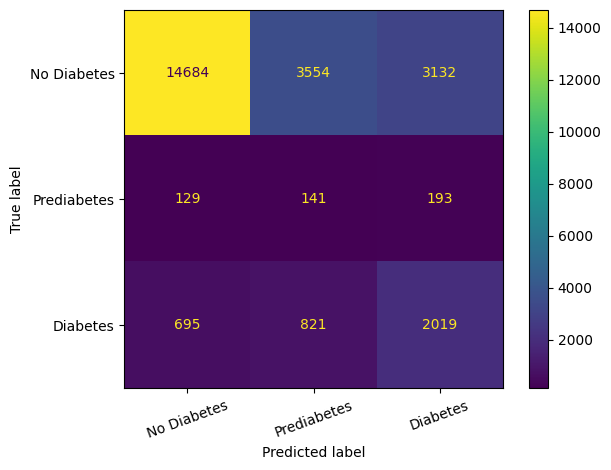

In [32]:

from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Reload the best model from Epoch 2
model.load_state_dict(
    torch.load(
        "/content/ft_transformer_best.pth",
        map_location=device,
        weights_only=True
    )
)

model.eval()

actual = []
predicted = []

# Evaluate on validation data
with torch.no_grad():
    for num, cat, labels in val_loader:
        outputs = model(
            num.to(device),
            cat.to(device)
        )

        predicted.extend(
            outputs.argmax(dim=1).cpu().tolist()
        )
        actual.extend(labels.tolist())

# Display performance for each diabetes class
print(classification_report(
    actual,
    predicted,
    labels=[0, 1, 2],
    target_names=[
        "No Diabetes",
        "Prediabetes",
        "Diabetes"
    ],
    zero_division=0
))

# Create confusion matrix
ConfusionMatrixDisplay.from_predictions(
    actual,
    predicted,
    labels=[0, 1, 2],
    display_labels=[
        "No Diabetes",
        "Prediabetes",
        "Diabetes"
    ]
)

plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig(
    "/content/ft_transformer_val_confusion.png",
    dpi=150
)
plt.show()


In [33]:
# Experiment: gentler class weighting

torch.manual_seed(42)

model_sqrt = FTTransformer(
    n_num=len(numerical_cols),
    cardinalities=cardinalities
).to(device)

# Calculate square-root class weights
sqrt_weights = torch.sqrt(
    class_counts.sum() / (3 * class_counts)
).to(device)

criterion_sqrt = nn.CrossEntropyLoss(
    weight=sqrt_weights
)

optimizer_sqrt = torch.optim.AdamW(
    model_sqrt.parameters(),
    lr=0.001
)

best_f1_sqrt = -1
history_sqrt = []

for epoch in range(3):
    model_sqrt.train()
    total_loss = 0

    # Training
    for num, cat, labels in train_loader:
        num = num.to(device)
        cat = cat.to(device)
        labels = labels.to(device)

        optimizer_sqrt.zero_grad()

        outputs = model_sqrt(num, cat)
        loss = criterion_sqrt(outputs, labels)

        loss.backward()
        optimizer_sqrt.step()

        total_loss += loss.item()

    # Validation
    model_sqrt.eval()
    actual = []
    predicted = []

    with torch.no_grad():
        for num, cat, labels in val_loader:
            outputs = model_sqrt(
                num.to(device),
                cat.to(device)
            )

            predicted.extend(
                outputs.argmax(dim=1).cpu().tolist()
            )
            actual.extend(labels.tolist())

    acc = accuracy_score(actual, predicted)
    macro_f1 = f1_score(
        actual, predicted,
        average="macro",
        zero_division=0
    )

    history_sqrt.append({
        "epoch": epoch + 1,
        "loss": total_loss / len(train_loader),
        "accuracy": acc,
        "macro_f1": macro_f1
    })

    print(
        f"Epoch {epoch+1}: "
        f"Accuracy={acc:.4f}, "
        f"Macro F1={macro_f1:.4f}"
    )

    if macro_f1 > best_f1_sqrt:
        best_f1_sqrt = macro_f1
        torch.save(
            model_sqrt.state_dict(),
            "/content/ft_transformer_sqrt_best.pth"
        )

print("\nOriginal best F1:", 0.4359)
print("New best F1:", round(best_f1_sqrt, 4))

Epoch 1: Accuracy=0.8167, Macro F1=0.4460
Epoch 2: Accuracy=0.8287, Macro F1=0.4435
Epoch 3: Accuracy=0.7924, Macro F1=0.4458

Original best F1: 0.4359
New best F1: 0.446


              precision    recall  f1-score   support

 No Diabetes       0.90      0.89      0.89     21370
 Prediabetes       0.00      0.00      0.00       463
    Diabetes       0.41      0.49      0.44      3535

    accuracy                           0.82     25368
   macro avg       0.44      0.46      0.45     25368
weighted avg       0.81      0.82      0.82     25368



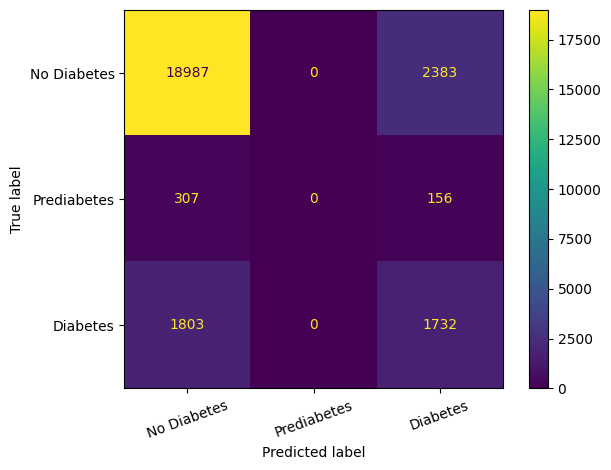

In [34]:

# Load the best model from our new experiment
model_sqrt.load_state_dict(
    torch.load(
        "/content/ft_transformer_sqrt_best.pth",
        map_location=device,
        weights_only=True
    )
)

model_sqrt.eval()

actual = []
predicted = []

with torch.no_grad():
    for num, cat, labels in val_loader:
        outputs = model_sqrt(
            num.to(device),
            cat.to(device)
        )

        predicted.extend(
            outputs.argmax(dim=1).cpu().tolist()
        )
        actual.extend(labels.tolist())

print(classification_report(
    actual,
    predicted,
    labels=[0, 1, 2],
    target_names=[
        "No Diabetes",
        "Prediabetes",
        "Diabetes"
    ],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    actual,
    predicted,
    labels=[0, 1, 2],
    display_labels=[
        "No Diabetes",
        "Prediabetes",
        "Diabetes"
    ]
)

plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig(
    "/content/ft_transformer_sqrt_confusion.png",
    dpi=150
)
plt.show()
